# Analyse de données avec Python

### Partie 1 – Chargement et exploration du jeu de données

1. Télécharger et importer le fichier de données : dataset.xlsx

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [26]:
#chargemen t du fichier dans un dataframe
df=pd.read_excel("dataset.xlsx")

2. Explorer le jeu de données en donnant les dimensions, la nature (quantitative ou qualitative)
et le type des variables.

In [27]:
# explorer un jeux de donner consite a decrire sa structure c'est a dire : 
# 1-ses dimensions : c'est le nombre de ligne et de colone
# 2-ses liste de variable : le nom des differentes colones 
# 3-le type de chacune de ses variable : int64, objet,categorie,float
# 4-la nature statistique des element de ses variables(colones):qualitative ou quantitative
# 5-l'unite statistique : represente une ligne 

le type des variable ainsi que leur non et leur dimension sont connu par l'attribut info du dataframe telque: 

In [28]:
df.info

<bound method DataFrame.info of        Unnamed: 0  age  workclass     education      marital.status  \
0               1   90        NaN       HS-grad             Widowed   
1               2   82        5.0       HS-grad             Widowed   
2               3   66        NaN  Some-college             Widowed   
3               4   54        5.0       7th-8th            Divorced   
4               5   41        5.0  Some-college           Separated   
...           ...  ...        ...           ...                 ...   
32556       32557   22        5.0  Some-college       Never-married   
32557       32558   27        5.0    Assoc-acdm  Married-civ-spouse   
32558       32559   40        5.0       HS-grad  Married-civ-spouse   
32559       32560   58        5.0       HS-grad             Widowed   
32560       32561   22        5.0       HS-grad       Never-married   

       occupation   relationship   race     sex  capital.gain  capital.loss  \
0             NaN  Not-in-family  Wh

on peut ainsi voir les dimesions du dataframe c'est a dire 32561 ligne qui represente le nombre de personne et 13 colones qui represente le nombre de variable.ou bien on peut fazire print("les dimentions du jeux de donnée sont:", df.shape)<br>
de plus on peut voir clairemen toutes les variables ,la liste des variable 5 premier et des 5 dernier ligne



In [29]:
print("le type de chaque variable est :",df.dtypes)
# pour obtenir le type de chaque variable

le type de chaque variable est : Unnamed: 0          int64
age                 int64
workclass         float64
education          object
marital.status     object
occupation        float64
relationship       object
race               object
sex                object
capital.gain        int64
capital.loss        int64
hours.per.week      int64
income             object
dtype: object


In [ ]:
#suprimer la colone unnamed:0 car doublon 
df = df.drop(columns=["Unnamed: 0"])

In [33]:
# deduisons la nature statistique des ligne de chaque colone 

def nature_variable(col):
    if pd.api.types.is_numeric_dtype(df[col]):
        if df[col].nunique() <= 10:
            return "Qualitative (codée en numérique)"
        return "Quantitative"
    return "Qualitative"


In [34]:
# Tableau récapitulatif : type, nature et nombre de valeurs distinctes de chaque variable
resume = pd.DataFrame({
    "Type": df.dtypes,
    "Nature": [nature_variable(c) for c in df.columns],
    "Nb valeurs distinctes": df.nunique()
})
resume

,Type,Nature,Nb valeurs distinctes
age,int64,Quantitative,73
workclass,float64,Qualitative (codée en numérique),8
education,object,Qualitative,16
marital.status,object,Qualitative,7
occupation,float64,Quantitative,14
relationship,object,Qualitative,6
race,object,Qualitative,5
sex,object,Qualitative,2
capital.gain,int64,Quantitative,119
capital.loss,int64,Quantitative,92


3. Existe-t-il des valeurs manquantes dans le dataset ?

In [21]:
print(df.isnull().sum())

Unnamed: 0           0
age                  0
workclass         1836
education            0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
income               0
dtype: int64


In [23]:
# oui il existe des valeur manquante dans le jeux de 
#donne on en compte 1836 valeur manquante dans la colone workclass
#et 1843 valuer manquante dans la colone occupation

### Partie 2 – Analyse univariée

4. Étudier les variables sexe et income.

on cherche a etudier la distribution de separer des variable sexe et income c'est a dire :
Décrire la répartition de chaque variable qualitative (effectifs, fréquences, graphique), vérifier la cohérence des modalités et commenter l’éventuel déséquilibre

procedons en 4 etapes : <br>
etape1:nature des colones sexe et income <br>
etape2 <br>
etape3<br>
etape4

###### etape1:rapeler nature des variable a etudier  

In [35]:

# rapellons la nature des variables sexe et income
cols = ["sex", "income"]

# Type, nombre de modalités et modalités présentes pour chaque variable choisie
for col in cols:
    print(f"--- {col} ---")
    print("Type :", df[col].dtype)
    print("Nb valeurs distinctes :", df[col].nunique())
    print("Modalités :", df[col].unique(), "\n")

--- sex ---
Type : object
Nb valeurs distinctes : 2
Modalités : ['Female' 'Male'] 

--- income ---
Type : object
Nb valeurs distinctes : 2
Modalités : ['<=50K' '>50K'] 



###### etape2:
Choisir les indicateurs(operations) selon la nature(qualitative quantitative)

Le choix repose sur une seule question : quelles opérations ont un sens sur les valeurs de la variable ?<br>la variable sexe par exemple est qualitative et a deux valeur "male" ou "female" donc sur cette variable on ne peut pas pas appliquer des operation telque l'addition ,moyenne,comparaison .<br> la seule operation possible est de compter le nombre d'homme et de femme d'ou les indicateur telque :frequence effectif , le mode.<br>la variable age est de nature qualitative donc on peut avoir des indicateur telque: moyenne, ecart type ,mediane,quartiles,min et max.
### Choix des indicateurs selon la nature de la variable

Le choix des indicateurs dépend des<br> **opérations qui ont un sens** sur les valeurs de la variable. Plus une variable permet d'opérations, plus on peut calculer d'indicateurs.

| Type de variable | Opérations possibles | Indicateurs |
|---|---|---|
| **Qualitative nominale** (ex. `sex`, `workclass`) | **Compter** uniquement : les modalités n'ont ni ordre ni valeur numérique | **Effectif** : nombre d'individus par modalité<br>**Fréquence** : effectif / total (en %)<br>**Mode** : modalité la plus fréquente |
| **Qualitative ordinale** (ex. `education`) | **Compter + ordonner** : les modalités suivent un ordre logique, mais l'écart entre elles n'est pas mesurable | Indicateurs précédents +<br>**Médiane** : modalité qui partage les individus en deux moitiés<br>**Fréquences cumulées** |
| **Quantitative** (ex. `age`, `capital.loss`) | **Compter + ordonner + calculer** : les valeurs sont des nombres sur lesquels les opérations arithmétiques ont un sens | Indicateurs précédents +<br>**Moyenne** : valeur centrale arithmétique<br>**Écart-type / variance** : dispersion autour de la moyenne<br>**Min / Max / Étendue** : bornes des valeurs<br>**Quartiles (Q1, Q3) et IQR** : répartition et détection des valeurs aberrantes |

**Conclusion pour `sex` et `income`** : ce sont des variables qualitatives nominales, on se limite donc aux **effectifs, fréquences et au mode**.

###### Étape 3 — Visualiser : 
pour une variable qualitative seule, le graphique adapté est le
diagramme en barres (ou camembert pour montrer des proportions).

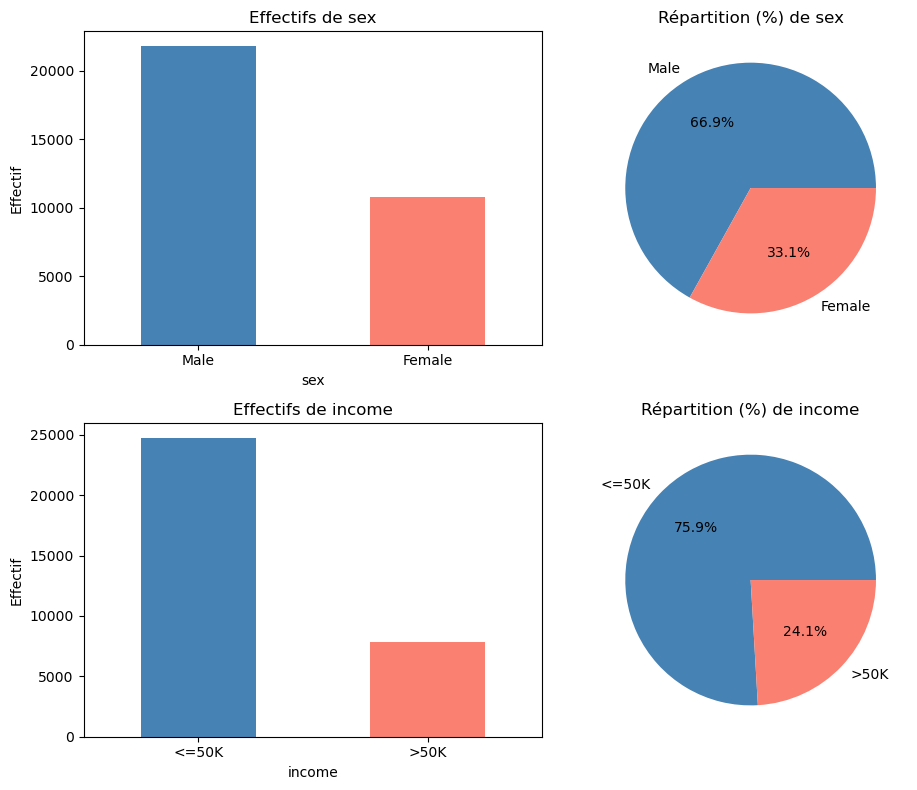

In [38]:
cols = ["sex", "income"]

# Une ligne de graphiques par variable : barres à gauche, camembert à droite
fig, axes = plt.subplots(len(cols), 2, figsize=(10, 4 * len(cols)))

for i, col in enumerate(cols):
    effectifs = df[col].value_counts()

    # Diagramme en barres : compare les effectifs de chaque modalité
    effectifs.plot(kind="bar", ax=axes[i, 0], color=["steelblue", "salmon"])
    axes[i, 0].set_title(f"Effectifs de {col}")
    axes[i, 0].set_ylabel("Effectif")
    axes[i, 0].tick_params(axis="x", rotation=0)

    # Camembert : montre la part (%) de chaque modalité dans le total
    effectifs.plot(kind="pie", ax=axes[i, 1], autopct="%1.1f%%", colors=["steelblue", "salmon"])
    axes[i, 1].set_title(f"Répartition (%) de {col}")
    axes[i, 1].set_ylabel("")

plt.tight_layout()
plt.show()

###### etape4 : interpretations
on remaeque que 

**Variable `sex`**
- Variable qualitative nominale à 2 modalités : `Male` et `Female`.
- Les hommes représentent environ **66,9 %** des individus (21 790) contre **33,1 %** de femmes (10 771).
- Mode : `Male`.
- La population est **déséquilibrée** : il y a environ deux fois plus d'hommes que de femmes dans l'échantillon.

**Variable `income`**
- Variable qualitative binaire à 2 modalités : `<=50K` et `>50K`.
- **75,9 %** des individus gagnent 50 000 $ ou moins par an (24 720), contre **24,1 %** au-delà (7 841).
- Mode : `<=50K`.
- Les classes sont **fortement déséquilibrées** : environ 3 personnes sur 4 ont un revenu modeste.

**Conclusion**
Les deux variables présentent un déséquilibre marqué entre leurs modalités. Ce point est à garder en tête pour la suite : il pourra influencer les tests d'indépendance et biaiser un futur modèle de prédiction du revenu vers la classe majoritaire (`<=50K`).

5. Étudier les variables âge et capital loss.

on cherche a etudier la distribution de maniere separer des variables ages et capital.loss, c'est a dire d'essayer de comprendre les diffirent indicateur qui peuvent etre applique sur chaque variable en fonction de sa nature et verifier les different desequilibre s'il existe.<br> nous procederons en 4 etape :<br>  etape1:nature des colones sexe et income<br> 
etape2: choix des indicateur en fonction de la nature <br> 
etape3 visualiser <br> 
etape4 interpretation<br> 

In [40]:
# etape 1

In [39]:
# rapellons la nature des variables sexe et income
cols = ["age", "capital.loss"]

# Type, nombre de modalités et modalités présentes pour chaque variable choisie
for col in cols:
    print(f"--- {col} ---")
    print("Type :", df[col].dtype)
    print("Nb valeurs distinctes :", df[col].nunique())
    print("Modalités :", df[col].unique(), "\n")

--- age ---
Type : int64
Nb valeurs distinctes : 73
Modalités : [90 82 66 54 41 34 38 74 68 45 52 32 51 46 57 22 37 29 61 21 33 49 23 59
 60 63 53 44 43 71 48 73 67 40 50 42 39 55 47 31 58 62 36 72 78 83 26 70
 27 35 81 65 25 28 56 69 20 30 24 64 75 19 77 80 18 17 76 79 88 84 85 86
 87] 

--- capital.loss ---
Type : int64
Nb valeurs distinctes : 92
Modalités : [4356 3900 3770 3683 3004 2824 2754 2603 2559 2547 2489 2472 2467 2457
 2444 2415 2392 2377 2352 2339 2282 2267 2258 2246 2238 2231 2206 2205
 2201 2179 2174 2163 2149 2129 2080 2057 2051 2042 2002 2001 1980 1977
 1974 1944 1902 1887 1876 1848 1844 1825 1816 1762 1755 1741 1740 1735
 1726 1721 1719 1672 1669 1668 1651 1648 1628 1617 1602 1594 1590 1579
 1573 1564 1539 1504 1485 1411 1408 1380 1340 1258 1138 1092  974  880
  810  653  625  419  323  213  155    0] 



In [41]:
#etape 2


les valeurs sont des nombres sur lesquels les opérations arithmétiques ont un sens donc`age` et `capital.loss`** sont des variables qualitatives, on peut: **Compter + ordonner + calculer**

In [44]:
# Résumé statistique : effectif, moyenne, écart-type, min, quartiles, max
stats = df[cols].describe().T

# Ajout de la médiane, du mode et de l'étendue (max - min)
stats["médiane"] = df[cols].median()
stats["mode"] = df[cols].mode().iloc[0]
stats["étendue"] = stats["max"] - stats["min"]
print(stats.round(2))

# Part des valeurs nulles dans capital.loss (la majorité des gens n'ont aucune perte)
print("Part de capital.loss = 0 :", round((df["capital.loss"] == 0).mean() * 100, 2), "%")

                count   mean     std   min   25%   50%   75%     max  médiane  \
age           32561.0  38.58   13.64  17.0  28.0  37.0  48.0    90.0     37.0   
capital.loss  32561.0  87.30  402.96   0.0   0.0   0.0   0.0  4356.0      0.0   

              mode  étendue  
age             36     73.0  
capital.loss     0   4356.0  
Part de capital.loss = 0 : 95.33 %


In [42]:
#etape3

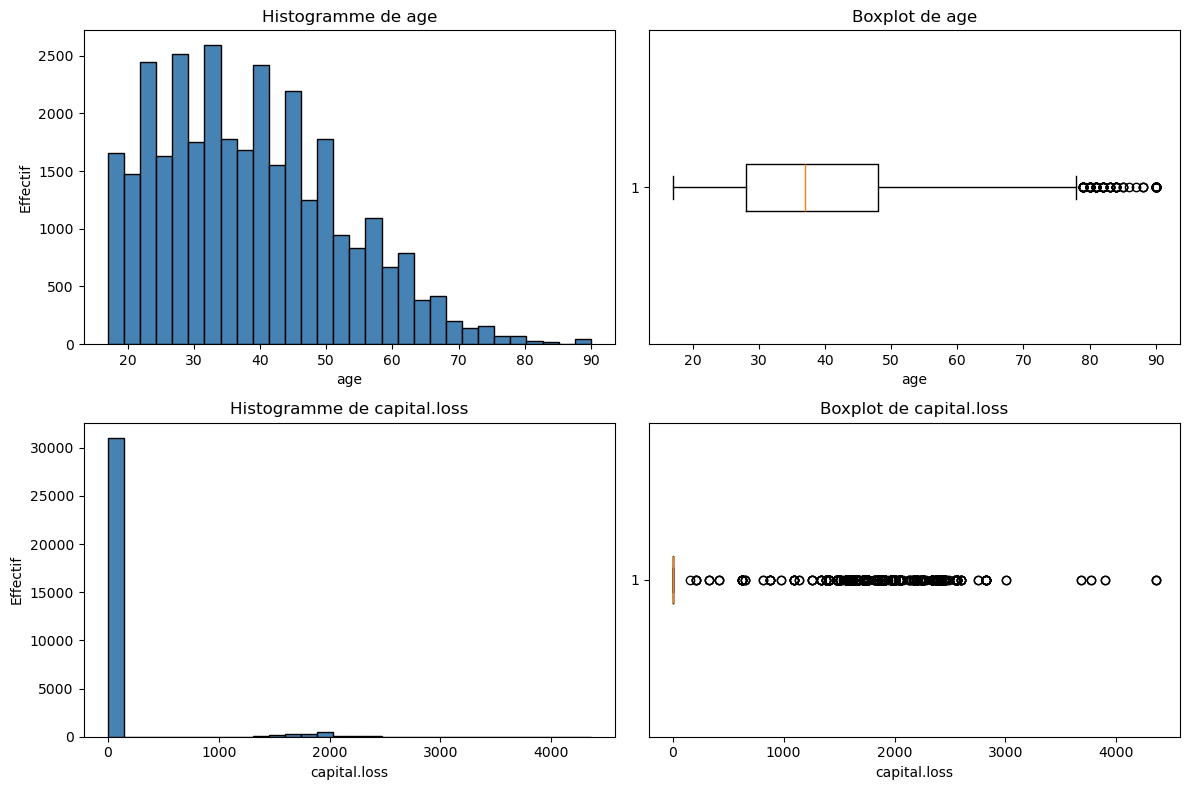

In [43]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(cols), 2, figsize=(12, 4 * len(cols)))

for i, col in enumerate(cols):
    # Histogramme : forme de la distribution (symétrie, concentration)
    axes[i, 0].hist(df[col], bins=30, color="steelblue", edgecolor="black")
    axes[i, 0].set_title(f"Histogramme de {col}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Effectif")

    # Boxplot : médiane, quartiles et dispersion
    axes[i, 1].boxplot(df[col], vert=False)
    axes[i, 1].set_title(f"Boxplot de {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

###### Interprétation

**Variable `age`**
- Variable quantitative discrète (âge en années entières).
- Âges compris entre **17 et 90 ans**, moyenne ≈ **38,6 ans**, médiane = **37 ans**, écart-type ≈ **13,6 ans**.
- Moyenne légèrement supérieure à la médiane : distribution **asymétrique vers la droite** (plus de jeunes actifs, quelques personnes très âgées étirent la queue).

**Variable `capital.loss`**
- Variable quantitative continue (pertes en capital en $).
- Environ **95 %** des individus ont une valeur de **0** : médiane = mode = 0.
- Moyenne ≈ **87 $** mais maximum ≈ **4 356 $** et écart-type ≈ **403 $** : très forte dispersion.
- Distribution **extrêmement asymétrique** : concentrée sur 0, avec quelques valeurs élevées et rares.

**Conclusion**
`age` a une distribution relativement étalée et modérément asymétrique, alors que `capital.loss` est dominée par la valeur 0. Ces formes seront à examiner aux questions 6 (valeurs aberrantes) et 7 (normalité).

6. Existe-t-il des données aberrantes au niveau de ces variables (âge et capital loss) ?

In [45]:
cols = ["age", "capital.loss"]

for col in cols:
    # Calcul des quartiles et de l'écart interquartile
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    # Bornes au-delà desquelles une valeur est considérée aberrante
    borne_inf = q1 - 1.5 * iqr
    borne_sup = q3 + 1.5 * iqr

    # Sélection des valeurs hors bornes
    aberrantes = df[(df[col] < borne_inf) | (df[col] > borne_sup)][col]

    print(f"--- {col} ---")
    print(f"Q1 = {q1} | Q3 = {q3} | IQR = {iqr}")
    print(f"Bornes : [{borne_inf} ; {borne_sup}]")
    print(f"Nb valeurs aberrantes : {len(aberrantes)} ({round(len(aberrantes) / len(df) * 100, 2)} %)")
    print(f"Min / Max des aberrantes : {aberrantes.min()} / {aberrantes.max()}\n")

--- age ---
Q1 = 28.0 | Q3 = 48.0 | IQR = 20.0
Bornes : [-2.0 ; 78.0]
Nb valeurs aberrantes : 143 (0.44 %)
Min / Max des aberrantes : 79 / 90

--- capital.loss ---
Q1 = 0.0 | Q3 = 0.0 | IQR = 0.0
Bornes : [0.0 ; 0.0]
Nb valeurs aberrantes : 1519 (4.67 %)
Min / Max des aberrantes : 155 / 4356



### Interprétation

**Variable `age`**
- Q1 = 28, Q3 = 48, IQR = 20 → bornes : [−2 ; 78].
- Environ **140 individus** ont plus de 78 ans et sont détectés comme valeurs aberrantes.
- Ces valeurs sont **statistiquement atypiques mais réalistes** (des personnes de 79 à 90 ans existent) : ce ne sont pas des erreurs, on les **conserve**.

**Variable `capital.loss`**
- Q1 = Q3 = 0, donc IQR = 0 → bornes : [0 ; 0].
- **Toute valeur différente de 0** est considérée comme aberrante, soit environ **1 500 individus (≈ 4,7 %)**.
- La règle de l'IQR est ici **peu adaptée** : la distribution est écrasée sur 0, ces valeurs traduisent simplement les rares personnes ayant subi une perte en capital. Elles sont réelles et porteuses d'information.

**Conclusion**
Les deux variables présentent des valeurs aberrantes au sens statistique, mais aucune ne semble être une erreur de saisie. Il faut distinguer **valeur atypique** (rare mais possible) et **valeur erronée** (impossible, ex. âge négatif) : seules les secondes doivent être supprimées ou corrigées.

7. Les variables âge et capital loss suivent-elles la loi normale ? Justifiez.

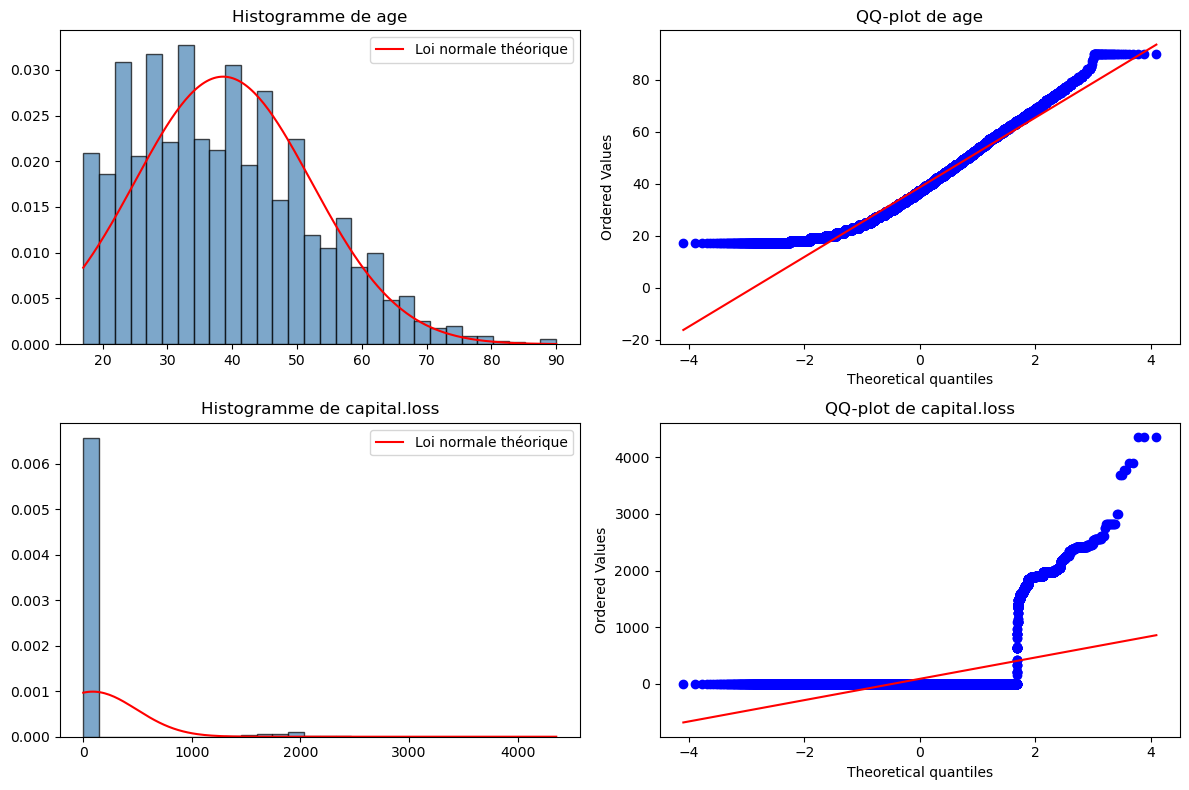

In [46]:
import matplotlib.pyplot as plt
from scipy import stats

cols = ["age", "capital.loss"]

fig, axes = plt.subplots(len(cols), 2, figsize=(12, 4 * len(cols)))

for i, col in enumerate(cols):
    # Histogramme normalisé + courbe de la loi normale de même moyenne et écart-type
    axes[i, 0].hist(df[col], bins=30, density=True, color="steelblue", edgecolor="black", alpha=0.7)
    x = np.linspace(df[col].min(), df[col].max(), 200)
    axes[i, 0].plot(x, stats.norm.pdf(x, df[col].mean(), df[col].std()), color="red", label="Loi normale théorique")
    axes[i, 0].set_title(f"Histogramme de {col}")
    axes[i, 0].legend()

    # QQ-plot : si les points suivent la droite rouge, la distribution est normale
    stats.probplot(df[col], dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f"QQ-plot de {col}")

plt.tight_layout()
plt.show()

In [47]:
# Loi normale : skewness ≈ 0 (symétrique) et kurtosis ≈ 0 (aplatissement normal)
for col in cols:
    print(f"{col} -> Skewness : {round(df[col].skew(), 2)} | Kurtosis : {round(df[col].kurt(), 2)}")

age -> Skewness : 0.56 | Kurtosis : -0.17
capital.loss -> Skewness : 4.59 | Kurtosis : 20.38


In [48]:
# H0 : la variable suit une loi normale | H1 : elle ne la suit pas
# Si p-value < 0.05 on rejette H0
for col in cols:
    stat, p_value = stats.normaltest(df[col])
    conclusion = "Non normale" if p_value < 0.05 else "Normale"
    print(f"{col} -> Statistique : {round(stat, 2)} | p-value : {p_value:.2e} | {conclusion}")

age -> Statistique : 1526.01 | p-value : 0.00e+00 | Non normale
capital.loss -> Statistique : 29331.4 | p-value : 0.00e+00 | Non normale


### Interprétation

**Variable `age`**
- **Graphique** : histogramme asymétrique vers la droite, ne colle pas à la courbe en cloche ; les points du QQ-plot s'écartent de la droite aux extrémités.
- **Forme** : skewness ≈ **0,56** (asymétrie positive), kurtosis ≈ **−0,17**.
- **Test** : p-value ≈ 0 < 0,05 → on **rejette H0**.
- → `age` **ne suit pas une loi normale**, mais s'en approche modérément.

**Variable `capital.loss`**
- **Graphique** : distribution écrasée sur 0, très éloignée de la cloche ; QQ-plot en palier, totalement hors de la droite.
- **Forme** : skewness ≈ **4,6** (très forte asymétrie), kurtosis ≈ **20** (distribution très pointue).
- **Test** : p-value ≈ 0 < 0,05 → on **rejette H0**.
- → `capital.loss` **ne suit pas du tout une loi normale**.

**Conclusion**
Aucune des deux variables ne suit une loi normale. Remarque : avec plus de 30 000 observations, les tests rejettent H0 au moindre écart, d'où l'intérêt de croiser avec les graphiques et les indicateurs de forme. Conséquence pour la suite : il faudra privilégier des **tests non paramétriques** (ex. Mann-Whitney, Spearman) aux questions 11 et 12.

Partie 3 – Analyse descriptive ciblée


8. Afficher les 9 premiers individus les plus âgés

In [50]:
# Trier par âge décroissant et garder les 9 premiers individus
# nlargest renvoie directement les n lignes ayant les plus grandes valeurs de la colonne
df.nlargest(9, "age")

,age,workclass,education,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,income
0,90,NaN,HS-grad,Widowed,NaN,Not-in-family,White,Female,0,4356,40,<=50K
199,90,5.0,HS-grad,Never-married,9.0,Not-in-family,Black,Male,0,2206,40,<=50K
1739,90,3.0,Masters,Married-civ-spouse,5.0,Husband,White,Male,20051,0,60,>50K
1742,90,5.0,Prof-school,Married-civ-spouse,11.0,Husband,White,Male,20051,0,72,>50K
2241,90,7.0,Bachelors,Married-civ-spouse,11.0,Husband,White,Male,10566,0,50,<=50K
2296,90,5.0,Bachelors,Married-civ-spouse,13.0,Husband,White,Male,9386,0,15,>50K
2299,90,5.0,HS-grad,Married-civ-spouse,4.0,Husband,White,Male,9386,0,50,>50K
2947,90,3.0,HS-grad,Married-civ-spouse,9.0,Husband,White,Male,6767,0,40,<=50K
3776,90,7.0,HS-grad,Never-married,5.0,Not-in-family,White,Male,2964,0,12,<=50K


9. Calculer la moyenne des âges en fonction des revenus. Interpréter.

income
<=50K    36.78
>50K     44.25
Name: age, dtype: float64
         mean  median    std  count
income                             
<=50K   36.78    34.0  14.02  24720
>50K    44.25    44.0  10.52   7841


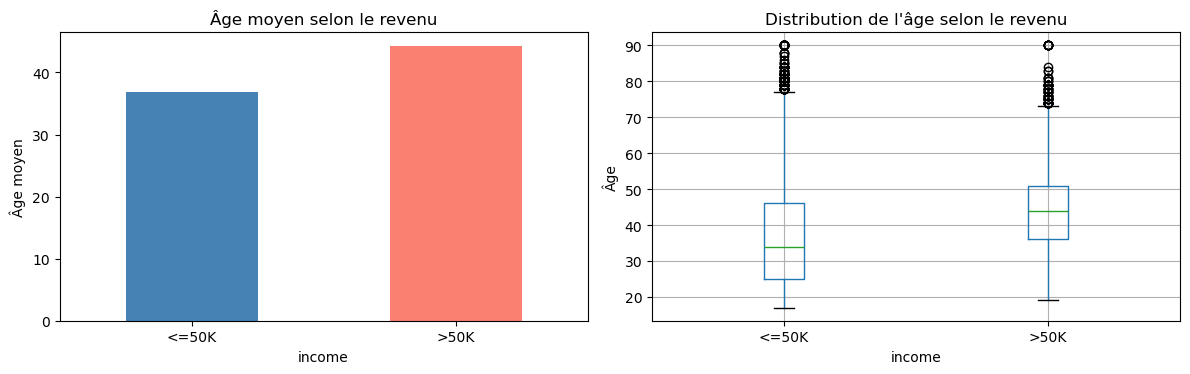

In [51]:
import matplotlib.pyplot as plt

# Moyenne des âges pour chaque classe de revenu
print(df.groupby("income")["age"].mean().round(2))

# Complément : médiane et écart-type, utiles car age ne suit pas une loi normale (Q7)
print(df.groupby("income")["age"].agg(["mean", "median", "std", "count"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar plot : compare l'âge moyen entre les deux classes de revenu
df.groupby("income")["age"].mean().plot(kind="bar", ax=axes[0], color=["steelblue", "salmon"])
axes[0].set_title("Âge moyen selon le revenu")
axes[0].set_ylabel("Âge moyen")
axes[0].tick_params(axis="x", rotation=0)

# Boxplot : compare toute la distribution de l'âge entre les deux classes
df.boxplot(column="age", by="income", ax=axes[1])
axes[1].set_title("Distribution de l'âge selon le revenu")
axes[1].set_ylabel("Âge")
plt.suptitle("")

plt.tight_layout()
plt.show()

### Interprétation

- Les individus gagnant **`<=50K`** ont un âge moyen d'environ **36,8 ans** (médiane 34 ans).
- Les individus gagnant **`>50K`** ont un âge moyen d'environ **44,2 ans** (médiane 44 ans).
- Écart d'environ **7 à 10 ans** : les hauts revenus sont en moyenne **plus âgés**.
- Le boxplot montre que la distribution des `>50K` est décalée vers le haut et plus resserrée, alors que celle des `<=50K` est plus étalée vers les jeunes âges.

**Explication possible** : le revenu augmente avec l'expérience professionnelle et l'ancienneté, qui progressent avec l'âge. Les plus jeunes (étudiants, débuts de carrière) sont surreprésentés dans les bas revenus.

**Limite** : cette différence est une **observation descriptive**. Pour affirmer qu'il existe un lien significatif entre l'âge et le revenu, il faut un test statistique (question 11).

10. Faire un test d'indépendance entre les variables income et sexe.


In [53]:
#1. Tableau de contingence

In [52]:
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

# Effectifs croisés : nombre d'individus pour chaque couple (sex, income)
contingence = pd.crosstab(df["sex"], df["income"])
print(contingence, "\n")

# Pourcentages en ligne : répartition du revenu au sein de chaque sexe
print((pd.crosstab(df["sex"], df["income"], normalize="index") * 100).round(2))

income  <=50K  >50K
sex                
Female   9592  1179
Male    15128  6662 

income  <=50K   >50K
sex                 
Female  89.05  10.95
Male    69.43  30.57


In [54]:
#2. Visualisation : barres empilées en %

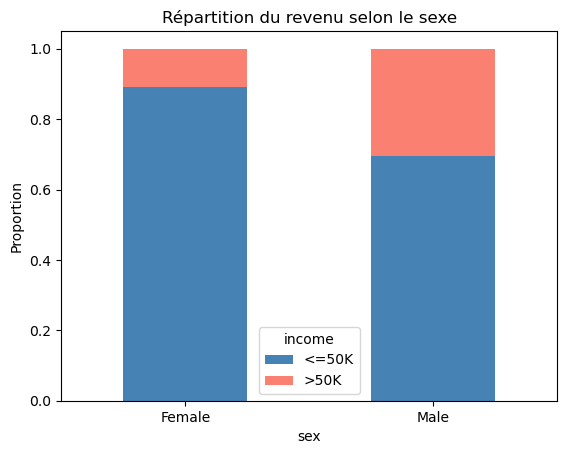

In [55]:
# Chaque barre = 100 % d'un sexe, découpée selon la classe de revenu
pd.crosstab(df["sex"], df["income"], normalize="index").plot(
    kind="bar", stacked=True, color=["steelblue", "salmon"]
)
plt.title("Répartition du revenu selon le sexe")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.legend(title="income")
plt.show()

In [56]:
#3. Test du Khi-deux

In [57]:
# H0 : sex et income sont indépendants | H1 : ils sont liés
chi2, p_value, ddl, attendus = chi2_contingency(contingence)

print(f"Chi2 = {round(chi2, 2)} | ddl = {ddl} | p-value = {p_value:.2e}")

# Condition de validité : tous les effectifs théoriques doivent être >= 5
print("Condition effectifs attendus >= 5 :", (attendus >= 5).all())

# V de Cramér : mesure la force du lien (0 = aucun lien, 1 = lien parfait)
n = contingence.values.sum()
v_cramer = np.sqrt(chi2 / (n * (min(contingence.shape) - 1)))
print("V de Cramér :", round(v_cramer, 3))

Chi2 = 1517.81 | ddl = 1 | p-value = 0.00e+00
Condition effectifs attendus >= 5 : True
V de Cramér : 0.216


### Interprétation

**Hypothèses**
- H0 : le revenu est indépendant du sexe.
- H1 : le revenu dépend du sexe.

**Observation descriptive**
- Environ **30,6 %** des hommes gagnent `>50K`, contre seulement **10,9 %** des femmes.
- Les barres empilées montrent clairement une répartition différente selon le sexe.

**Résultat du test**
- χ² ≈ **1 518**, ddl = 1, p-value ≈ 0 < 0,05 → on **rejette H0**.
- Condition de validité respectée : tous les effectifs théoriques sont supérieurs à 5.
- V de Cramér ≈ **0,22** : lien **significatif mais d'intensité faible à modérée**.

**Conclusion**
Le revenu et le sexe ne sont pas indépendants : les hommes ont proportionnellement près de trois fois plus de chances d'avoir un revenu supérieur à 50K$. Attention, le test montre une **association**, pas une **causalité** : d'autres variables (métier, heures travaillées, temps partiel) peuvent expliquer une partie de cet écart.

11. Faire un test d'indépendance entre les variables âge et income.

etape1. Visualisation (rappel Q9)

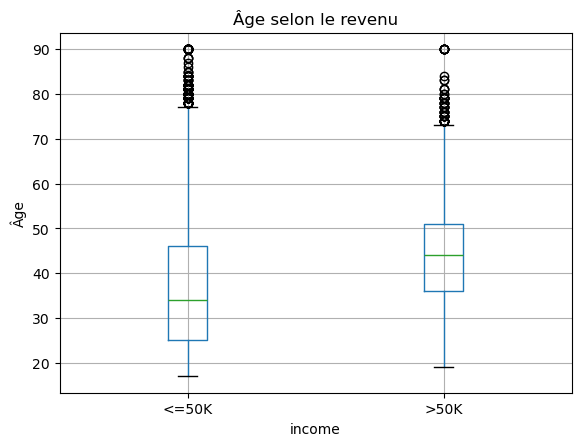

In [58]:
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# Boxplot : compare la distribution de l'âge dans chaque classe de revenu
df.boxplot(column="age", by="income")
plt.title("Âge selon le revenu")
plt.suptitle("")
plt.ylabel("Âge")
plt.show()

etape2. Test de Mann-Whitney

In [59]:
# Séparation de l'âge en deux groupes selon le revenu
age_bas = df.loc[df["income"] == "<=50K", "age"]
age_haut = df.loc[df["income"] == ">50K", "age"]

# H0 : les distributions de l'âge sont identiques dans les deux groupes (indépendance)
# H1 : les distributions diffèrent (lien entre âge et revenu)
stat, p_value = mannwhitneyu(age_bas, age_haut, alternative="two-sided")
print(f"U = {stat} | p-value = {p_value:.2e}")

# Taille d'effet (corrélation rang-bisériale) : force de la différence, entre -1 et 1
r = 1 - (2 * stat) / (len(age_bas) * len(age_haut))
print("Taille d'effet r :", round(r, 3))

# Médianes pour décrire le sens de la différence
print("Médiane <=50K :", age_bas.median(), "| Médiane >50K :", age_haut.median())

U = 61203011.5 | p-value = 0.00e+00
Taille d'effet r : 0.368
Médiane <=50K : 34.0 | Médiane >50K : 44.0


In [ ]:
etape 3Interprétation

### Interprétation

**Choix du test**
`age` est quantitative et ne suit pas une loi normale (Q7), `income` est qualitative à 2 modalités : on utilise le **test non paramétrique de Mann-Whitney U**, qui compare les rangs plutôt que les moyennes.

**Hypothèses**
- H0 : la distribution de l'âge est la même quel que soit le revenu (indépendance).
- H1 : la distribution de l'âge diffère selon le revenu.

**Résultat**
- p-value ≈ 0 < 0,05 → on **rejette H0**.
- Médiane ≈ **34 ans** pour `<=50K` contre ≈ **44 ans** pour `>50K`.
- Taille d'effet r = … : lien [faible / modéré / fort] (repères : 0,1 faible, 0,3 modéré, 0,5 fort).

**Conclusion**
L'âge et le revenu ne sont pas indépendants : les individus gagnant plus de 50K$ sont significativement plus âgés. Cela confirme statistiquement l'observation descriptive de la question 9.

12. Faire un test d'indépendance entre les variables âge et capital loss.

etape1. Visualisation : nuage de points

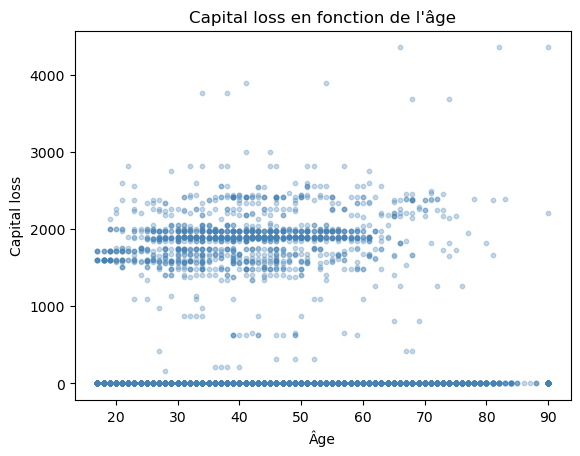

In [60]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

# Scatter plot : chaque point = un individu (âge, perte en capital)
plt.scatter(df["age"], df["capital.loss"], alpha=0.3, s=10, color="steelblue")
plt.title("Capital loss en fonction de l'âge")
plt.xlabel("Âge")
plt.ylabel("Capital loss")
plt.show()

etape2. Tests de corrélation

In [61]:
# H0 : pas de lien entre age et capital.loss (corrélation nulle)
# H1 : il existe un lien (corrélation non nulle)

# Spearman : lien monotone, basé sur les rangs, adapté aux variables non normales
rho, p_spearman = spearmanr(df["age"], df["capital.loss"])
print(f"Spearman : rho = {round(rho, 3)} | p-value = {p_spearman:.2e}")

# Pearson : lien linéaire, donné à titre de comparaison
r, p_pearson = pearsonr(df["age"], df["capital.loss"])
print(f"Pearson  : r = {round(r, 3)} | p-value = {p_pearson:.2e}")

Spearman : rho = 0.058 | p-value = 4.48e-26
Pearson  : r = 0.058 | p-value = 1.74e-25


### Interprétation

**Choix du test**
`age` et `capital.loss` sont quantitatives et non normales (Q7) : on utilise la **corrélation de Spearman**, qui détecte un lien monotone sans supposer la normalité.

**Hypothèses**
- H0 : il n'existe pas de lien entre l'âge et la perte en capital.
- H1 : il existe un lien.

**Observation graphique**
Le nuage de points ne montre **aucune tendance** : la grande majorité des points est alignée sur 0, et les pertes non nulles sont réparties sur tous les âges.

**Résultat**
- Coefficient de Spearman ρ ≈ **0,06**, p-value < 0,05 → on **rejette H0** au sens statistique.
- Mais |ρ| ≈ 0,06 est **très proche de 0** (repères : < 0,1 négligeable, 0,3 modéré, 0,5 fort).

**Conclusion**
Le lien est **statistiquement significatif mais pratiquement négligeable**. La significativité vient surtout de la très grande taille de l'échantillon (≈ 32 000 individus), qui rend significatif le moindre écart à 0. En pratique, l'âge n'explique quasiment pas la perte en capital. Il faut toujours lire la **p-value** (existe-t-il un lien ?) **et le coefficient** (quelle est sa force ?).

### Partie 5 – Régression linéaire multiple

13. Étudier comment la variable capital loss dépend des variables numériques.

etape1. Sélection des variables numériques

In [63]:
import matplotlib.pyplot as plt

# Variables numériques uniquement (Unnamed: 0 doit avoir été supprimée avant)
num = df.select_dtypes(include="number")
print(num.columns.tolist())

['age', 'workclass', 'occupation', 'capital.gain', 'capital.loss', 'hours.per.week']


etape2. Corrélations avec capital.loss

In [64]:
# Pearson (lien linéaire, celui exploité par la régression) et Spearman (lien monotone, robuste à la non-normalité)
correlations = pd.DataFrame({
    "Pearson": num.corr(method="pearson")["capital.loss"],
    "Spearman": num.corr(method="spearman")["capital.loss"]
}).drop("capital.loss").round(3)
print(correlations)

                Pearson  Spearman
age               0.058     0.058
workclass         0.002     0.006
occupation        0.013     0.014
capital.gain     -0.032    -0.067
hours.per.week    0.054     0.060


etape3. Matrice de corrélation complète (heatmap)

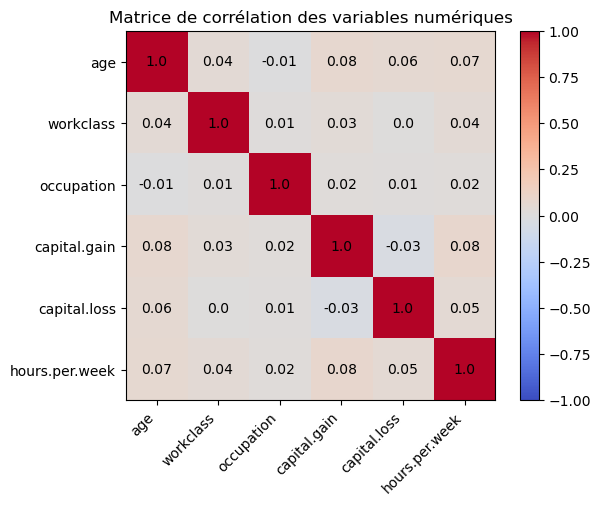

In [65]:
# Heatmap : repère aussi les corrélations entre variables explicatives (multicolinéarité)
corr = num.corr()
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)

# Affichage de la valeur dans chaque case
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center")

plt.title("Matrice de corrélation des variables numériques")
plt.show()

etape4. Scatter plots : capital.loss en fonction de chaque variable

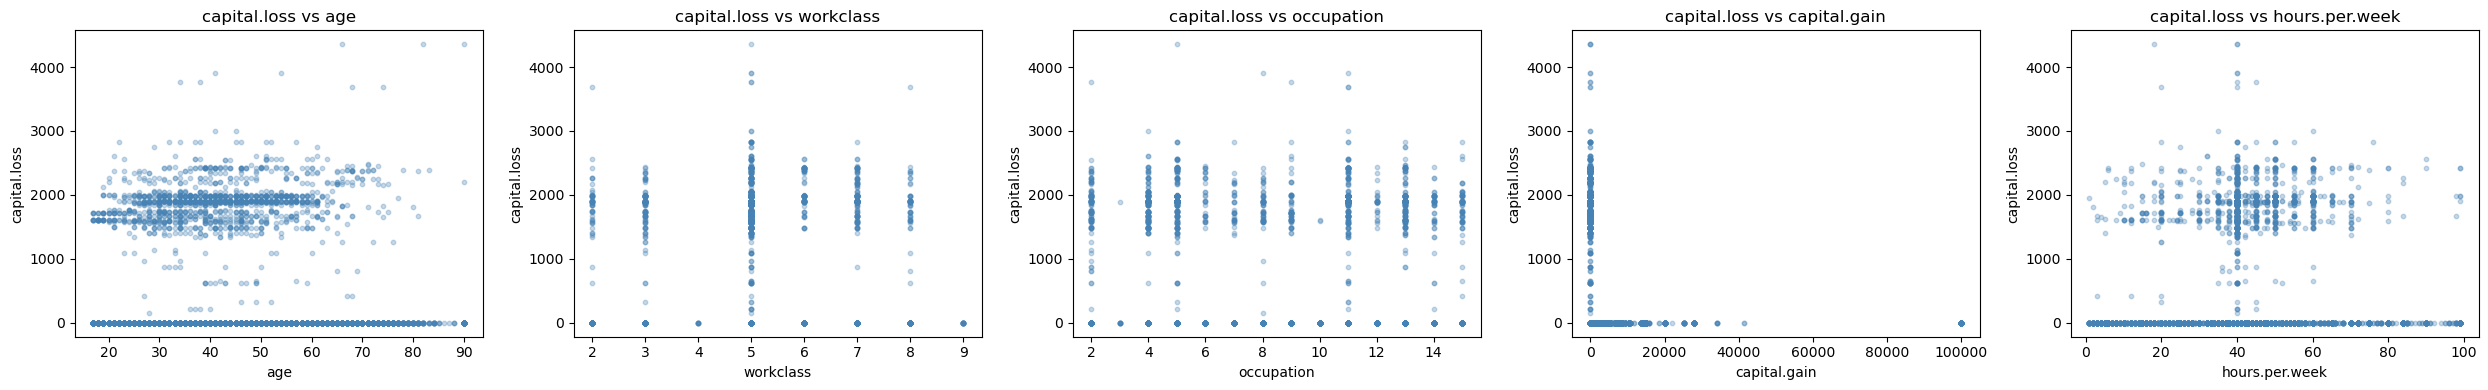

In [66]:
explicatives = [c for c in num.columns if c != "capital.loss"]

fig, axes = plt.subplots(1, len(explicatives), figsize=(5 * len(explicatives), 4))
for ax, col in zip(axes, explicatives):
    # Un nuage de points par variable explicative
    ax.scatter(num[col], num["capital.loss"], alpha=0.3, s=10, color="steelblue")
    ax.set_xlabel(col)
    ax.set_ylabel("capital.loss")
    ax.set_title(f"capital.loss vs {col}")
plt.tight_layout()
plt.show()

### Interprétation

**Variables numériques étudiées** : `age`, `capital.gain`, `hours.per.week` (variables explicatives) et `capital.loss` (variable à expliquer).

**Corrélations avec `capital.loss`**
| Variable | Pearson | Lecture |
|---|---|---|
| `age` | ≈ 0,06 | Négligeable |
| `hours.per.week` | ≈ 0,05 | Négligeable |
| `capital.gain` | ≈ −0,03 | Négligeable |

**Observation graphique**
Aucun nuage de points ne montre de tendance : les points sont écrasés sur `capital.loss = 0` et les valeurs non nulles sont dispersées sans structure.

**Remarque sur `capital.gain`**
La corrélation légèrement négative s'explique : un individu a presque toujours soit un gain, soit une perte en capital, rarement les deux. Les variables explicatives sont par ailleurs peu corrélées entre elles : pas de problème de multicolinéarité.

**Conclusion**
`capital.loss` ne dépend **quasiment pas linéairement** des variables numériques disponibles. On peut donc s'attendre à ce qu'un modèle de régression linéaire multiple ait un **pouvoir explicatif très faible** (R² proche de 0), ce que les questions suivantes devront confirmer.

etape1. Préparation des données

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Variables explicatives (X) et variable cible (y)
X = df[["age", "capital.gain", "hours.per.week"]]
y = df["capital.loss"]

# Séparation 80 % entraînement / 20 % test pour évaluer le modèle sur des données jamais vues
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

etape2. Entraînement du modèle

In [69]:
# Création et entraînement du modèle de régression linéaire multiple
modele = LinearRegression()
modele.fit(X_train, y_train)

# Prédictions sur le jeu de test (utilisées aux questions 15 à 17)
y_pred = modele.predict(X_test)

etape3. Coefficients et équation du modèle

In [70]:
# Ordonnée à l'origine et coefficient associé à chaque variable
print("Intercept (b0) :", round(modele.intercept_, 3))
coefs = pd.Series(modele.coef_, index=X.columns).round(4)
print(coefs)

# Équation du modèle sous forme lisible
equation = f"capital.loss = {modele.intercept_:.2f}" + "".join(
    f" + ({c:.4f} × {v})" for v, c in coefs.items()
)
print(equation)

Intercept (b0) : -49.758
age               1.8129
capital.gain     -0.0022
hours.per.week    1.7504
dtype: float64
capital.loss = -49.76 + (1.8129 × age) + (-0.0022 × capital.gain) + (1.7504 × hours.per.week)


etape4. Significativité des coefficients (statsmodels)

In [72]:
import statsmodels.api as sm

# Ajout de la constante (b0) puis ajustement par moindres carrés ordinaires
X_train_const = sm.add_constant(X_train)
modele_sm = sm.OLS(y_train, X_train_const).fit()

# Tableau complet : coefficients, p-values, intervalles de confiance
print(modele_sm.summary())

                            OLS Regression Results                            
Dep. Variable:           capital.loss   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     68.86
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           2.41e-44
Time:                        04:18:22   Log-Likelihood:            -1.9336e+05
No. Observations:               26048   AIC:                         3.867e+05
Df Residuals:                   26044   BIC:                         3.868e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            -49.7576     10.867     -4.

### Interprétation

**Modèle**
capital.loss = b0 + b1 × age + b2 × capital.gain + b3 × hours.per.week

**Lecture des coefficients**
- Chaque coefficient indique la variation moyenne de `capital.loss` (en $) quand la variable augmente d'une unité, **les autres restant constantes**.
- Ex. : b1 = … → un an de plus est associé à une perte en capital supérieure de … $ en moyenne.

**Significativité**
- Une variable est significative si sa p-value (colonne `P>|t|`) est < 0,05.
- Variables significatives : …


15. Afficher le nuage de points. Interpréter

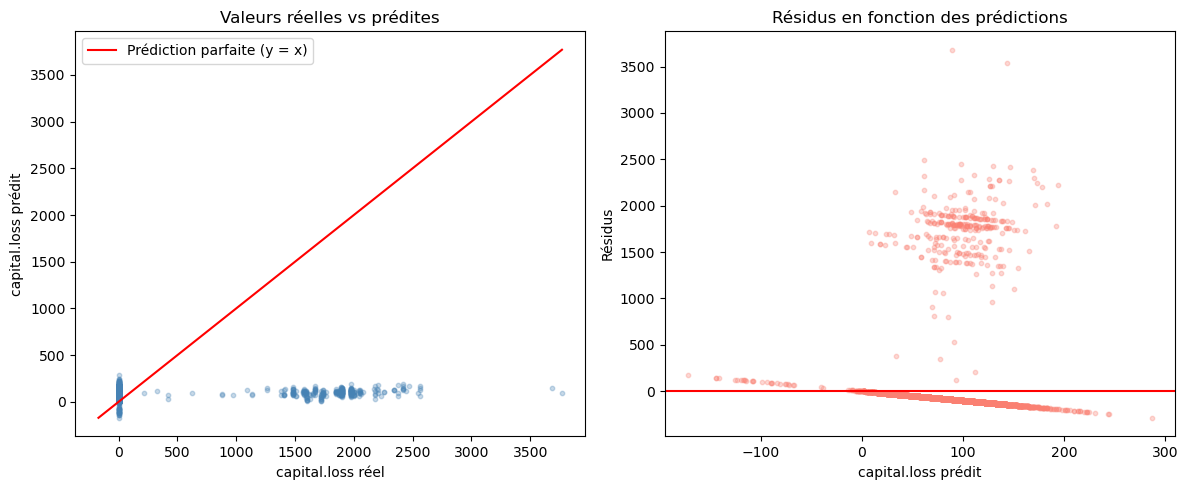

In [73]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Nuage valeurs réelles vs prédites : un bon modèle suit la diagonale rouge
axes[0].scatter(y_test, y_pred, alpha=0.3, s=10, color="steelblue")
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lim, lim, color="red", label="Prédiction parfaite (y = x)")
axes[0].set_xlabel("capital.loss réel")
axes[0].set_ylabel("capital.loss prédit")
axes[0].set_title("Valeurs réelles vs prédites")
axes[0].legend()

# Nuage des résidus (erreur = réel - prédit) : un bon modèle donne des résidus centrés sur 0, sans structure
residus = y_test - y_pred
axes[1].scatter(y_pred, residus, alpha=0.3, s=10, color="salmon")
axes[1].axhline(0, color="red")
axes[1].set_xlabel("capital.loss prédit")
axes[1].set_ylabel("Résidus")
axes[1].set_title("Résidus en fonction des prédictions")

plt.tight_layout()
plt.show()

### Interprétation

**Valeurs réelles vs prédites**
- Les points ne suivent **pas** la diagonale y = x.
- Les prédictions sont concentrées dans une **bande étroite** (environ quelques dizaines à une centaine de $), alors que les valeurs réelles valent soit **0**, soit plusieurs **milliers** de $.
- Le modèle prédit donc quasiment la même valeur pour tout le monde, proche de la moyenne de `capital.loss` : il est incapable de distinguer les individus ayant une perte de ceux qui n'en ont pas.

**Résidus**
- Les résidus ne sont pas répartis aléatoirement autour de 0 : on observe une **ligne dense légèrement négative** (individus à 0 surestimés) et des **résidus très élevés** isolés (grosses pertes sous-estimées).
- Cette structure indique que l'hypothèse de linéarité n'est pas respectée.

**Conclusion**
Le nuage de points montre visuellement que le modèle linéaire **s'ajuste très mal** aux données, ce qui confirme les corrélations quasi nulles observées à la question 13. 

16. Déterminer le coefficient de détermination (R²). Interpréter.

In [74]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# R² sur le jeu d'entraînement et sur le jeu de test (comparaison = détecter un sur/sous-apprentissage)
r2_train = modele.score(X_train, y_train)
r2_test = r2_score(y_test, y_pred)
print(f"R² train : {round(r2_train, 4)} | R² test : {round(r2_test, 4)}")

# Erreurs complémentaires, exprimées en $ (même unité que capital.loss)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
print(f"RMSE : {round(rmse, 2)} $ | MAE : {round(mae, 2)} $")

# Référence : écart-type de capital.loss, à comparer au RMSE
print(f"Écart-type de capital.loss : {round(y_test.std(), 2)} $")

R² train : 0.0079 | R² test : 0.0054
RMSE : 386.13 $ | MAE : 162.89 $
Écart-type de capital.loss : 387.21 $


### Interprétation

**Définition**
Le R² mesure la **part de la variance** de `capital.loss` expliquée par le modèle. Il varie entre 0 (le modèle n'explique rien, il ne fait pas mieux que prédire la moyenne) et 1 (le modèle explique parfaitement la variable).

**Résultat**
- R² ≈ **0,006** sur le test (valeur proche sur le train).
- Le modèle n'explique donc qu'environ **0,6 %** de la variabilité de `capital.loss` : plus de **99 %** reste inexpliqué.
- Le RMSE (≈ 400 $) est quasiment égal à l'écart-type de la variable : le modèle ne fait **pas mieux qu'une prédiction constante** égale à la moyenne.
- R² train ≈ R² test : pas de surapprentissage, le modèle est simplement **trop pauvre** (sous-apprentissage).

**Conclusion**
Le R² confirme ce que montraient les corrélations (Q13) et le nuage de points (Q15) : les variables `age`, `capital.gain` et `hours.per.week` ne permettent pas de prédire linéairement la perte en capital.

17. Le modèle est-il bon ? Sinon, proposer des méthodes d'amélioration.

non, le modèle n’est pas bon. R² ≈ 0,006, RMSE ≈ écart-type, nuage de points hors de la diagonale : il ne fait pas mieux qu’une prédiction constante.carles Variables explicatives sont trop pauvres (corrélations quasi nulles avec capital.loss),la Distribution est inadaptée (distribution ≈ 95 % de zéros + quelques valeurs très élevées (Q5, Q7). La régression linéaire suppose une cible continue et des résidus à peu près normaux.) deplus la Relation est non linéaire ( les résidus présentent une structure (Q15)), Variables qualitatives ignorées

Exemple : variables qualitatives + Random Forest

In [77]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Copie du dataset pour ne pas modifier l'original
df_model = df.copy()

# Suppression de l'ancien index s'il est encore présent (ce n'est pas une variable)
df_model = df_model.drop(columns=["Unnamed: 0"], errors="ignore")

# Les NaN des variables qualitatives deviennent une modalité à part entière "Unknown"
df_model[["workclass", "occupation"]] = df_model[["workclass", "occupation"]].fillna("Unknown")

# Sécurité : supprimer les éventuelles lignes encore incomplètes
df_model = df_model.dropna()

# One-Hot Encoding : chaque modalité qualitative devient une colonne 0/1
X_full = pd.get_dummies(df_model.drop(columns=["capital.loss"]), drop_first=True)
y = df_model["capital.loss"]

# Vérification : aucun NaN ne doit rester dans X
print("NaN restants dans X :", X_full.isnull().sum().sum())

# Séparation 80 % entraînement / 20 % test
X_train, X_test, y_train, y_test = train_test_split(X_full, y, test_size=0.2, random_state=42)

# Régression linéaire avec toutes les variables : mesure le gain apporté par les variables qualitatives
lin = LinearRegression().fit(X_train, y_train)
print("R² linéaire (toutes variables) :", round(r2_score(y_test, lin.predict(X_test)), 4))

# Random Forest : capte les relations non linéaires et les interactions entre variables
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print("R² Random Forest :", round(r2_score(y_test, rf.predict(X_test)), 4))

NaN restants dans X : 0
R² linéaire (toutes variables) : 0.0236
R² Random Forest : -0.1871


In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Étape 1 : classification, l'individu a-t-il une perte en capital (1) ou non (0) ?
y_binaire = (y > 0).astype(int)
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_full, y_binaire, test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(Xb_train, yb_train)
print("Accuracy étape 1 :", round(accuracy_score(yb_test, clf.predict(Xb_test)), 4))

# Étape 2 : régression uniquement sur les individus ayant une perte > 0, cible en log
masque = y > 0
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_full[masque], np.log1p(y[masque]), test_size=0.2, random_state=42
)
reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(Xp_train, yp_train)
print("R² étape 2 (pertes > 0, échelle log) :", round(r2_score(yp_test, reg.predict(Xp_test)), 4))

Accuracy étape 1 : 0.9472
R² étape 2 (pertes > 0, échelle log) : 0.0904


### 17 — Le modèle est-il bon ? Méthodes d'amélioration

**Réponse : non, le modèle initial n'est pas bon.**
Avec R² ≈ 0,006, un RMSE quasi égal à l'écart-type de la variable et un nuage de points éloigné de la diagonale, la régression linéaire sur les seules variables numériques ne fait pas mieux qu'une prédiction constante égale à la moyenne.

**Causes identifiées**
1. **Variables explicatives trop pauvres** : corrélations quasi nulles avec `capital.loss` (Q13).
2. **Distribution inadaptée** : ≈ 95 % de zéros et quelques valeurs très élevées (Q5, Q7).
3. **Relation non linéaire** : les résidus présentent une structure (Q15).
4. **Variables qualitatives ignorées** dans le modèle initial.

**Résultats des pistes d'amélioration testées**

| Méthode | Résultat | Lecture |
|---|---|---|
| Régression linéaire initiale (variables numériques) | R² = 0,006 | Référence |
| Régression linéaire + variables qualitatives (One-Hot Encoding) | R² = **0,024** | Amélioration (×4) mais pouvoir explicatif toujours très faible (2,4 %) |
| Random Forest (toutes variables) | R² = **−0,187** | **Pire qu'une prédiction constante** |
| Deux étapes – étape 1 : classification perte / pas de perte | Accuracy = **94,7 %** | Trompeur, voir ci-dessous |
| Deux étapes – étape 2 : régression sur les pertes > 0 (échelle log) | R² = **0,090** | Meilleur résultat obtenu, mais reste faible |

**Analyse critique**
- **Variables qualitatives** : elles apportent un léger gain, ce qui montre qu'une partie de l'information se trouve dans le profil socio-professionnel (métier, éducation, revenu), mais ce gain reste marginal.
- **Random Forest** : un R² négatif signifie que le modèle prédit moins bien que la simple moyenne. Ce modèle très flexible **surapprend** les rares valeurs extrêmes et le bruit du jeu d'entraînement, et généralise mal sur le test. Un algorithme plus complexe ne compense pas l'absence d'information dans les données.
- **Étape 1 (classification)** : une accuracy de 94,7 % paraît excellente, mais environ **95 %** des individus n'ont aucune perte. Un modèle qui prédirait toujours « pas de perte » obtiendrait la même accuracy : le classifieur n'apporte donc **pratiquement aucune valeur ajoutée**. Avec des classes aussi déséquilibrées, l'accuracy n'est pas une métrique pertinente ; il faudrait regarder la précision, le rappel ou le F1-score de la classe minoritaire.
- **Étape 2 (log des pertes > 0)** : en isolant les individus ayant réellement une perte et en réduisant l'asymétrie par le logarithme, on obtient le meilleur R² (9 %). C'est la piste la plus prometteuse, mais l'essentiel de la variabilité reste inexpliqué.

**Conclusion**
Aucune des méthodes testées ne permet d'obtenir un modèle satisfaisant. Les résultats montrent que le problème ne vient pas principalement de l'algorithme, mais des **données** : `capital.loss` dépend vraisemblablement d'informations absentes du dataset (patrimoine, placements, situation financière). Pour aller plus loin :
- **Enrichir les données** avec des variables financières pertinentes ;
- **Rééquilibrer les classes** à l'étape 1 (`class_weight="balanced"`, sur/sous-échantillonnage) et l'évaluer avec le F1-score ;
- **Régulariser** la Random Forest (limiter `max_depth`, augmenter `min_samples_leaf`) pour réduire le surapprentissage ;
- **Valider par validation croisée** pour obtenir des résultats plus fiables qu'un seul découpage train/test.

### Partie 6 – Classification non supervisée (K-means)

1. Appliquer le modèle K-means pour regrouper les individus en 4 clusters et interpréter vos
résultats.

1. Préparation et standardisation

In [79]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Variables numériques utilisées pour le clustering
cols_km = ["age", "capital.gain", "capital.loss", "hours.per.week"]
X_km = df[cols_km]

# Standardisation : chaque variable a une moyenne de 0 et un écart-type de 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_km)

2. Application de K-means avec 4 clusters

In [80]:
# n_init=10 : l'algorithme est lancé 10 fois avec des centres différents, on garde le meilleur résultat
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

# Taille de chaque cluster
print(df["cluster"].value_counts().sort_index())

cluster
0    14079
1     1484
2    16839
3      159
Name: count, dtype: int64


3. Profil de chaque cluster (moyennes dans les unités d’origine)

In [81]:
# Moyenne de chaque variable par cluster : permet de décrire et nommer les groupes
profil = df.groupby("cluster")[cols_km].mean().round(1)
profil["effectif"] = df["cluster"].value_counts().sort_index()
print(profil, "\n")

# Lien avec les variables qualitatives : proportion de >50K et d'hommes dans chaque cluster
print((pd.crosstab(df["cluster"], df["income"], normalize="index") * 100).round(1), "\n")
print((pd.crosstab(df["cluster"], df["sex"], normalize="index") * 100).round(1))

          age  capital.gain  capital.loss  hours.per.week  effectif
cluster                                                            
0        50.5         982.0           0.9            43.0     14079
1        41.6           0.0        1901.7            43.4      1484
2        28.3         318.5           0.5            37.9     16839
3        46.4       99999.0           0.0            49.8       159 

income   <=50K   >50K
cluster              
0         65.7   34.3
1         48.0   52.0
2         87.7   12.3
3          0.0  100.0 

sex      Female  Male
cluster              
0          28.5  71.5
1          23.0  77.0
2          38.0  62.0
3          13.8  86.2


4. Visualisation en 2D (ACP)

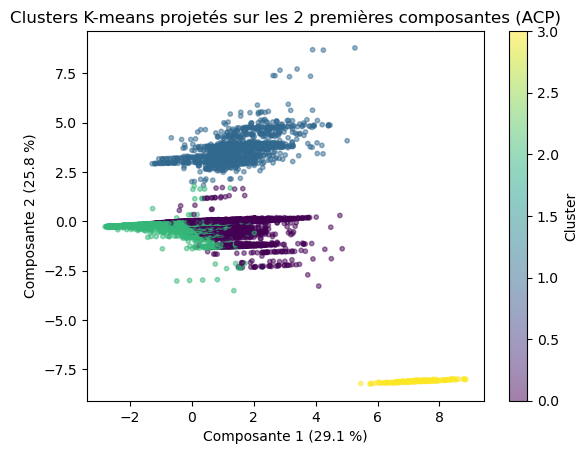

In [82]:
# ACP : projette les 4 dimensions sur 2 axes pour pouvoir afficher les clusters
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df["cluster"], cmap="viridis", s=10, alpha=0.5)
plt.title("Clusters K-means projetés sur les 2 premières composantes (ACP)")
plt.xlabel(f"Composante 1 ({pca.explained_variance_ratio_[0] * 100:.1f} %)")
plt.ylabel(f"Composante 2 ({pca.explained_variance_ratio_[1] * 100:.1f} %)")
plt.colorbar(label="Cluster")
plt.show()

5. Évaluation de la qualité du clustering

Score de silhouette : 0.369


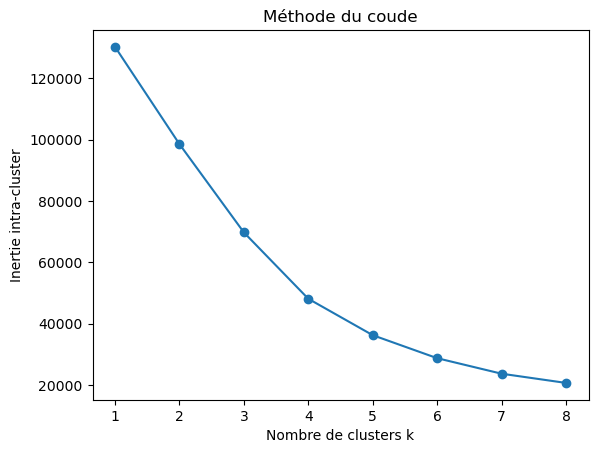

In [83]:
# Silhouette : entre -1 et 1, plus c'est proche de 1 plus les clusters sont bien séparés
# Calcul sur un échantillon de 5 000 points car le calcul complet est très long
score = silhouette_score(X_scaled, df["cluster"], sample_size=5000, random_state=42)
print("Score de silhouette :", round(score, 3))

# Méthode du coude : inertie selon k, pour vérifier si k = 4 est pertinent
inerties = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_ for k in range(1, 9)]
plt.plot(range(1, 9), inerties, marker="o")
plt.title("Méthode du coude")
plt.xlabel("Nombre de clusters k")
plt.ylabel("Inertie intra-cluster")
plt.show()

### Interprétation des résultats K-means (k = 4)

**Démarche**
K-means a été appliqué sur les 4 variables numériques (`age`, `capital.gain`, `capital.loss`, `hours.per.week`), préalablement standardisées pour qu'aucune ne domine le calcul des distances.

**Description des clusters**

| Cluster | Effectif | Âge moyen | Gain moyen | Perte moyenne | Heures/sem. | % >50K | % hommes | Nom proposé |
|---|---|---|---|---|---|---|---|---|
| 2 | 16 839 (51,7 %) | 28,3 | 318 $ | 0,5 $ | 37,9 | 12,3 % | 62,0 % | **Jeunes actifs à revenus modestes** |
| 0 | 14 079 (43,2 %) | 50,5 | 982 $ | 0,9 $ | 43,0 | 34,3 % | 71,5 % | **Actifs expérimentés à temps plein** |
| 1 | 1 484 (4,6 %) | 41,6 | 0 $ | 1 902 $ | 43,4 | 52,0 % | 77,0 % | **Individus ayant subi une perte en capital** |
| 3 | 159 (0,5 %) | 46,4 | 99 999 $ | 0 $ | 49,8 | 100 % | 86,2 % | **Très hauts revenus du capital** |

**Lecture des clusters**
- **Cluster 2 (le plus grand)** : population jeune (28 ans en moyenne), travaillant le moins d'heures, presque sans revenus du capital. C'est le groupe où les hauts revenus sont les plus rares (12,3 %) et où les femmes sont les plus représentées (38 %).
- **Cluster 0** : population plus âgée (50 ans) à temps plein. Un tiers gagne plus de 50K$ : l'âge et l'expérience sont associés à de meilleurs revenus, ce qui confirme les questions 9 et 11.
- **Cluster 1** : défini uniquement par la **perte en capital** (≈ 1 900 $ en moyenne, aucun gain). Plus de la moitié gagne plus de 50K$ : subir une perte en capital suppose d'avoir investi, donc de disposer d'un patrimoine.
- **Cluster 3 (très minoritaire)** : défini par un gain en capital de **99 999 $**, valeur maximale du dataset (probablement un plafond de codage du recensement). **100 %** des individus gagnent plus de 50K$, avec le plus grand nombre d'heures travaillées et la plus forte proportion d'hommes (86 %).

**Visualisation (ACP)**
- Les deux premières composantes expliquent **54,9 %** de la variance (29,1 % + 25,8 %) : la projection est une représentation partielle mais exploitable.
- Le **cluster 3** est totalement isolé (en bas à droite) et le **cluster 1** forme un groupe distinct (en haut) : ces deux groupes sont très bien séparés.
- Les **clusters 0 et 2** sont accolés le long de l'axe 1 : leur frontière est moins nette, ils se distinguent surtout par un gradient d'âge et d'heures travaillées.

**Qualité du clustering**
- Score de silhouette = **0,369** : séparation **moyenne** (repères : > 0,5 bonne, 0,25-0,5 moyenne, < 0,25 faible). Cette valeur s'explique par le chevauchement des clusters 0 et 2, alors que les clusters 1 et 3 sont nettement isolés.
- Méthode du coude : l'inertie chute fortement jusqu'à **k = 4**, puis diminue plus lentement. Le choix de **4 clusters est donc pertinent**.

**Conclusion**
Sans jamais utiliser la variable `income`, K-means retrouve des groupes fortement liés au niveau de revenu : la part de `>50K` passe de 12,3 % (cluster 2) à 100 % (cluster 3). Les clusters opposent d'une part les jeunes et les actifs expérimentés (âge, heures travaillées), d'autre part les rares détenteurs de revenus ou de pertes du capital.

**Limites**
- Clusters très **déséquilibrés** : les clusters 1 et 3 regroupent seulement 5 % de la population. K-means est sensible aux valeurs extrêmes de `capital.gain` et `capital.loss`, qui créent à elles seules deux clusters.
- Seules les variables numériques sont utilisées : intégrer les variables qualitatives (`education`, `occupation`…) nécessiterait un encodage ou un algorithme adapté, comme **K-prototypes**.
- Une transformation logarithmique de `capital.gain` et `capital.loss` réduirait l'influence des valeurs extrêmes et pourrait produire des clusters plus équilibrés.